# F03.03c · Predicción por paciente: un modelo para cada persona

> 🧭 **En 30 segundos**
> - **Para qué:** F03.03b vio que **un solo modelo para todos** no encuentra señal preictal en TUSZ cuando se le quita la pista de la grabación. Pero en la literatura lo que mejor funciona es **un modelo por paciente**: el "aviso" de cada persona es distinto. Aquí se prueba eso con los pacientes que tienen **varias crisis en varias sesiones**.
> - **Entra:** las ventanas de **F02.03** (`ventanas.csv`), la señal de **F02.02** y el inventario de **F01.01** → **Sale:** la nota de cada paciente (AUC con su intervalo), cuántos pacientes se pueden predecir de verdad (frente a un **control de falsas crisis**) y qué crisis se habrían avisado.
> - **Idea clave:** cada sesión del paciente se puntúa con un modelo entrenado **solo con sus otras sesiones**. El modelo nunca ha visto la grabación que puntúa, así que no puede reconocerla: si acierta, es porque ve algo **antes de la crisis** que se repite de un día a otro en esa persona.

> 📍 **Dónde estamos: Fase 3 · después de F03.03b (F03.03c).** No cambia lo que recibe la red (eso lo decide F03.03b). Es otra pregunta: ¿se puede predecir **dentro de cada paciente**?

> 🔄 **Es dinámico.** Las cifras, el veredicto y las conclusiones salen de los datos al ejecutarlo.

> 🔒 **🟢 eval no se usa** (salvo que se ponga `INCLUIR_EVAL = True` al final, para confirmar con más pacientes). Aquí no se ajusta nada con los datos: los modelos y las reglas están fijados antes de mirar.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Un perro de alerta de crisis no aprende "cómo son las crisis de todo el mundo": aprende **las de su dueño**. Hace lo mismo un modelo por paciente: aprende cómo cambia el EEG de **esa persona** antes de **sus** crisis.

| Pregunta | Dónde se responde |
|---|---|
| ¿Qué pacientes tienen datos para esto (varias crisis, varias sesiones)? | §3 |
| ¿Cuántas de sus crisis son **líderes** (sin otra crisis justo antes)? | §4 |
| ¿Funciona la cadena por paciente? (detectar ⚡ crisis frente a 💤, que debe salir alto) | §6 |
| ¿Se puede **predecir** (⏳ frente a 💤) dentro de cada paciente? ¿Más de lo que daría la suerte? | §7-§8 (recuadro dorado) |
| ¿Funciona mejor en algún grupo de inicio (focal, generalizada, ausencia)? | §9 |

### Las tres trampas que se evitan

| Trampa | Cómo se evita |
|---|---|
| **Reconocer la grabación** (F03.03b) | Cada sesión se puntúa con un modelo que no la ha visto (*leave-one-session-out*). Además se mide la nota con ⏳ y 💤 de la **misma sesión** |
| **Contar ventanas como si fueran independientes** (dos ventanas seguidas son casi iguales: el intervalo saldría demasiado estrecho) | El intervalo se calcula sorteando **bloques**: cada crisis, y cada 5 min de 💤 |
| **Que salga algún paciente "predecible" por suerte** (con 20 pacientes, alguno sale) | **Control de falsas crisis**: se repite todo con ⏳ falsas (trozos de 💤 al azar). Los "predecibles" de verdad tienen que ser **más** que los que salen con crisis falsas |

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Sesión** | Un día de grabación de un paciente (`aaaaaajy_s003`), con uno o varios ficheros |
| **Dejar una sesión fuera** | Entrenar con todas las sesiones del paciente menos una y puntuar esa. Se repite con cada sesión |
| **Crisis líder** | Una crisis sin otra en los 30 min anteriores de su grabación. Su ⏳ es "antes de una crisis" y no "recuperándose de la anterior" (F03.03b vio que 2 de cada 3 ⏳ están en racimos) |
| **Paciente predecible** | Su AUC con el intervalo del 95 % **entero por encima de 0,5** |
| **Crisis avisada** | Con un umbral que salta en el 10 % de los ratos tranquilos del paciente, la mayor parte de los 2 min de antes de la crisis está por encima |
| **Control de falsas crisis** | Lo mismo, pero con ⏳ inventadas (trozos de 💤): mide cuántos pacientes salen "predecibles" sin que haya nada que predecir |

## 0. Los parámetros

> 🎯 **Qué hacemos:** elegir el conjunto y si se usan también los pacientes de 🟢 eval.

- `CONJUNTO`: el de toda la Fase 3 (`tfm_comun/prediccion/estudio.py`). Aquí solo marca la carpeta de resultados: las ⏳ son las del **modelo general** (umbral de 3 min).
- `INCLUIR_EVAL`: `False` para estudiar y decidir. Ponerlo a `True` **solo al final**, para confirmar con los pacientes de eval (cada modelo es de un paciente, así que no se mezcla nada; pero la regla de la fase es no mirarlos hasta el final).

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill.)*

In [1]:
CONJUNTO = None        # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3)
INCLUIR_EVAL = False   # True solo al final, para confirmar con los pacientes de 🟢 eval

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar que están instaladas (las mismas que F03.03) e importar lo necesario.

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_CONTEXTO
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_CONTEXTO)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características


Todo lo necesario está instalado.


In [3]:
# 1) Recarga automática de tfm_comun (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

# 2) Librerías de siempre
import json
import re
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import scipy
import sklearn
from sklearn.metrics import roc_auc_score
import xgboost
from tqdm.auto import tqdm
from IPython.display import display, Markdown

# 3) tfm_comun: rutas, características y contexto (lo mismo que F03.03)
from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_03, RUTA_SENALES, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.configuracion import leer_configuracion
from tfm_comun.senal.montaje import CANALES_TCP
from tfm_comun.prediccion.umbrales import UMBRAL_LEADIN_POR_DEFECTO_S, SPH_POR_DEFECTO_S
from tfm_comun.prediccion.caracteristicas import nombres_caracteristicas
from tfm_comun.prediccion.almacen_caracteristicas import caracteristicas_al_dia, guardar_caracteristicas, cargar_caracteristicas
from tfm_comun.prediccion.contextos.duracion import ventanas_por_contexto
from tfm_comun.prediccion.contextos.disponibilidad import con_contexto_completo, inicios_necesarios, clave
from tfm_comun.prediccion.contextos.calculo import caracteristicas_de_inicios
from tfm_comun.prediccion.contextos.indices import cubo_contexto
from tfm_comun.prediccion.contextos.resumen import resumir_contexto
from tfm_comun.prediccion.tokens_vecinos import leer_inventario

# 4) tfm_comun: predicción por paciente (nuevo en F03.03c)
from tfm_comun.prediccion.por_paciente import (leer_ventanas, pacientes_candidatos, muestrear_interictal, minutos_desde_crisis_anterior,
                                               es_lider, grupos_bootstrap, pseudo_preictal, validar_dejando_sesion, auroc_por_bloques,
                                               auroc_misma_sesion, crisis_avisadas, resumen_pacientes)
from tfm_comun.prediccion.linea_base import NOMBRES_MODELO

# 5) tfm_comun: cómo se enseñan las cosas
from tfm_comun.visual.iconos import con_icono
from tfm_comun.visual.colores import COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

# 6) Versiones y conjunto
versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, xgboost)
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
xgboost     3.4.1


✅ **Qué deberías ver:** la tabla de librerías con ✅ y sus versiones.

## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" **antes de mirar** los resultados.
>
> 🤔 **Por qué:** con un modelo por paciente hay muchas formas de elegir lo que más conviene a la vista de los datos (qué modelo, qué contexto, qué pacientes). Para que la conclusión valga, la **combinación principal** y las reglas se fijan aquí; el resto se enseña como complemento.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `MINIMO_CRISIS`, `MINIMO_SESIONES` | 5 · 2 | Para entrar: al menos 5 crisis con ⏳, en al menos 2 sesiones |
| `MINIMO_CRISIS_LIDERES` | 3 | Para medir con solo crisis líderes: al menos 3, en al menos 2 sesiones |
| `MAX_INTERICTAL_PACIENTE` | 4.000 | 💤 por paciente como mucho (≈ 4,4 h), repartidas entre sus sesiones, en trozos seguidos |
| `CONTEXTOS` | 4 s · 60 s | Sin contexto y con el contexto que mejor fue en F03.03 |
| `MODELOS_PROBAR` | regresión logística (C = 0,01) · XGBoost (profundidad 3, 200 árboles) | Fijos: no se ajustan por paciente (con 5-10 crisis, ajustar sería sobreajustar) |
| `PRINCIPAL` | 60 s · regresión logística · todas las crisis | La combinación que decide el veredicto (la mejor entre pacientes en F03.03) |
| `LIDER_MIN` | 30 min | Sin crisis antes para ser crisis líder |
| `ESPECIFICIDAD`, `N_BOOTSTRAP` | 0,9 · 500 | Umbral de "crisis avisada" · sorteos del intervalo |

In [4]:
MINIMO_CRISIS = 5
MINIMO_SESIONES = 2
MINIMO_CRISIS_LIDERES = 3
MAX_INTERICTAL_PACIENTE = 4000
CONTEXTOS = [4, 60]
MODELOS_PROBAR = {'logistica': {'C': 0.01}, 'xgboost': {'max_depth': 3, 'n_estimators': 200, 'learning_rate': 0.05}}
CRISIS_PROBAR = ['todas', 'líderes']
PRINCIPAL = (60, 'logistica', 'todas')
LIDER_MIN = 30
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500

In [5]:
# 1) Carpeta de resultados y lo que dejó F03.01 (semilla y tamaño de ventana)
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/03c_por_paciente')
config_01 = leer_configuracion(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)', CONJUNTO)
SEMILLA = int(config_01['semilla'])
VENTANA_S = config_01['ventana_s']
MUESTRAS = int(config_01['muestras_por_ventana'])
FS = MUESTRAS / VENTANA_S
SPLITS_PACIENTES = ['train', 'dev'] + (['eval'] if INCLUIR_EVAL else [])
DURACION_PREICTAL_S = UMBRAL_LEADIN_POR_DEFECTO_S - SPH_POR_DEFECTO_S        # 120 s en el modelo general
K_MAX = ventanas_por_contexto(max(CONTEXTOS), VENTANA_S)
NOMBRES = nombres_caracteristicas(CANALES_TCP)
assert PRINCIPAL[0] in CONTEXTOS and PRINCIPAL[1] in MODELOS_PROBAR and PRINCIPAL[2] in CRISIS_PROBAR
print(f'Conjunto (carpeta): {CONJUNTO} · pacientes de: {", ".join(con_icono(s) for s in SPLITS_PACIENTES)} · preictal: {DURACION_PREICTAL_S} s · '
      f'principal: {PRINCIPAL[0]} s · {NOMBRES_MODELO[PRINCIPAL[1]]} · {PRINCIPAL[2]} las crisis')

Conjunto (carpeta): general · pacientes de: 🔵 train, 🟡 dev · preictal: 120 s · principal: 60 s · regresión logística · todas las crisis


## 3. Los pacientes y sus ventanas

> 🎯 **Qué hacemos:** (1) leer las ventanas de F02.03 (⏳ del modelo general, 💤 y ⚡, sin las rechazadas); (2) quedarnos con los pacientes con al menos `MINIMO_CRISIS` crisis con ⏳ en al menos `MINIMO_SESIONES` sesiones; (3) elegir sus 💤 (como mucho `MAX_INTERICTAL_PACIENTE`, repartidas entre sesiones); (4) quitar las ventanas sin los 60 s de contexto completos.
>
> 🤔 **Por qué:** con menos crisis no hay con qué aprender, y con una sola sesión no se puede dejar ninguna fuera. Las 💤 se recortan porque hay pacientes con 100 horas: sin tope, uno solo pesaría más que todos los demás juntos y tardaría mucho.

In [6]:
# 1) Ventanas y candidatos
ventanas = leer_ventanas(SPLITS_PACIENTES)
candidatos = pacientes_candidatos(ventanas, MINIMO_CRISIS, MINIMO_SESIONES)
v = ventanas[ventanas.patient.isin(candidatos.index[candidatos.entra])].reset_index(drop=True)

# 2) 💤: como mucho MAX_INTERICTAL_PACIENTE por paciente, en trozos seguidos repartidos entre sus sesiones
interictal = v[v.etiqueta == 0].reset_index(drop=True)
interictal = interictal[muestrear_interictal(interictal, MAX_INTERICTAL_PACIENTE, SEMILLA)]

# 3) ⏳ y 💤 con el contexto completo más largo (las mismas filas para todos los contextos); ⚡ aparte (solo 4 s)
pre_inter = pd.concat([v[v.etiqueta == 1], interictal], ignore_index=True)
filas = pre_inter[con_contexto_completo(pre_inter, K_MAX, MUESTRAS)].reset_index(drop=True)
ictales = v[v.etiqueta == -1].reset_index(drop=True)

# 4) Volver a comprobar los mínimos tras quitar ventanas
pre = filas[filas.etiqueta == 1]
cuenta = pre.groupby('patient').agg(crisis=('crisis_id', 'nunique'), sesiones=('sesion', 'nunique'))
PACIENTES = sorted(cuenta.index[(cuenta.crisis >= MINIMO_CRISIS) & (cuenta.sesiones >= MINIMO_SESIONES)])
filas = filas[filas.patient.isin(PACIENTES)].reset_index(drop=True)
ictales = ictales[ictales.patient.isin(PACIENTES)].reset_index(drop=True)
filas['id_ventana'] = filas.id_tramo.astype(str) + '_' + filas.muestra_inicio.astype(int).astype(str).str.zfill(9)
assert PACIENTES, '🔴 Ningún paciente cumple los mínimos.'

# 5) Tabla de pacientes
tabla_pacientes = candidatos.loc[PACIENTES, ['split', 'grupo', 'tipos']].copy()
por_paciente = filas.groupby('patient')
solo_pre = filas[filas.etiqueta == 1].groupby('patient')
tabla_pacientes['crisis con ⏳'] = solo_pre.crisis_id.nunique()
tabla_pacientes['sesiones'] = por_paciente.sesion.nunique()
tabla_pacientes['sesiones con ⏳'] = solo_pre.sesion.nunique()
tabla_pacientes['⏳ ventanas'] = por_paciente.etiqueta.apply(lambda e: int((e == 1).sum()))
tabla_pacientes['💤 ventanas'] = por_paciente.etiqueta.apply(lambda e: int((e == 0).sum()))
tabla_pacientes['⚡ ventanas'] = ictales.groupby('patient').size().reindex(PACIENTES).fillna(0).astype(int)
tabla_pacientes.index.name = 'paciente'
quedan = candidatos[candidatos.entra]
display(Markdown(f'**{len(PACIENTES)} pacientes** (de {len(quedan)} con los mínimos antes de quitar ventanas sin contexto; '
                 f'{len(candidatos)} pacientes tienen alguna ⏳) · {numero_legible(int((filas.etiqueta == 1).sum()))} ⏳ · '
                 f'{numero_legible(int((filas.etiqueta == 0).sum()))} 💤 · {numero_legible(len(ictales))} ⚡'))
display(con_separadores(tabla_pacientes.assign(split=tabla_pacientes.split.map(con_icono), grupo=tabla_pacientes.grupo.map(con_icono))))

**21 pacientes** (de 21 con los mínimos antes de quitar ventanas sin contexto; 130 pacientes tienen alguna ⏳) · 13.568 ⏳ · 48.102 💤 · 16.092 ⚡

,split,grupo,tipos,crisis con ⏳,sesiones,sesiones con ⏳,⏳ ventanas,💤 ventanas,⚡ ventanas
paciente,,,,,,,,,
aaaaaccj,🔵 train,🔹 ausencia,absz,6,3,3,337,319,24
aaaaahie,🟡 dev,♦️ focal,fnsz,41,32,9,2.289,3.510,1.557
aaaaajfq,🔵 train,focal/generalizada,cpsz/fnsz/gnsz,6,12,3,338,2.799,218
aaaaajqo,🔵 train,♦️ focal,cpsz,11,17,3,575,3.705,1.586
aaaaalfs,🔵 train,♦️ focal,fnsz,5,3,3,268,105,373
aaaaammu,🔵 train,🔷 generalizada,tnsz,5,4,2,287,1.312,134
aaaaampk,🟡 dev,focal/generalizada,fnsz/gnsz,19,9,2,847,2.822,979
aaaaamqq,🟡 dev,focal/generalizada,fnsz/gnsz,10,11,5,517,3.552,1.377
aaaaanme,🔵 train,focal/generalizada,fnsz/gnsz,21,11,4,1.206,3.625,994


👀 **Cómo leer la tabla.** Una fila por paciente que entra: su partición, grupo de inicio y tipos de crisis, cuántas crisis con ⏳ tiene y en cuántas sesiones, y cuántas ventanas de cada clase se usan.

✅ **Qué deberías ver:** unos 20-25 pacientes de 🔵 train y 🟡 dev. Los que tienen pocas sesiones con ⏳ (2) son los más difíciles: cada ronda entrena con muy pocas crisis.

## 4. Crisis líderes: ⏳ que son "antes de una crisis" y no "después de la anterior"

> 🎯 **Qué hacemos:** para cada crisis con ⏳, los minutos desde el final de la crisis anterior en su grabación (suponiendo que los tokens consecutivos van seguidos, como en F02.03). Es **líder** si pasan al menos `LIDER_MIN` minutos o si es la primera de la grabación.
>
> 🤔 **Por qué:** F03.03b vio que casi 2 de cada 3 ⏳ están a pocos minutos de otra crisis. Si un paciente sale "predecible" solo con esas, el modelo puede estar viendo **el después de la crisis anterior**. Con las líderes, no.

In [7]:
edfs_inventario, crisis_inventario = leer_inventario()
es_pre = filas.etiqueta.to_numpy() == 1
minutos = minutos_desde_crisis_anterior(filas[es_pre], edfs_inventario, crisis_inventario)
filas['minutos_desde_crisis_anterior'] = np.nan
filas.loc[es_pre, 'minutos_desde_crisis_anterior'] = minutos.to_numpy()
filas['lider'] = False
filas.loc[es_pre, 'lider'] = es_lider(minutos, LIDER_MIN)

por_crisis = filas[es_pre].groupby(['patient', 'crisis_id']).agg(minutos=('minutos_desde_crisis_anterior', 'first'), lider=('lider', 'first'),
                                                                   sesion=('sesion', 'first'))
franjas = pd.cut(por_crisis.minutos, [0, 10, 20, LIDER_MIN, 120, np.inf],
                 labels=['< 10 min', '10-20 min', f'20-{LIDER_MIN} min', f'{LIDER_MIN}-120 min', '> 120 min']).astype(object).fillna('primera de la grabación')
display(Markdown('**Crisis con ⏳ según el tiempo desde la crisis anterior:**'))
display(con_separadores(franjas.value_counts().rename('crisis').to_frame()))
lideres = por_crisis[por_crisis.lider].groupby('patient').agg(lideres=('lider', 'size'), sesiones_con_lideres=('sesion', 'nunique'))
tabla_pacientes['crisis líderes'] = lideres.lideres.reindex(PACIENTES).fillna(0).astype(int)
tabla_pacientes['sesiones con líderes'] = lideres.sesiones_con_lideres.reindex(PACIENTES).fillna(0).astype(int)
CON_LIDERES = [p for p in PACIENTES if tabla_pacientes.loc[p, 'crisis líderes'] >= MINIMO_CRISIS_LIDERES
               and tabla_pacientes.loc[p, 'sesiones con líderes'] >= MINIMO_SESIONES]
print(f'{int(por_crisis.lider.sum())} de {len(por_crisis)} crisis son líderes · {len(CON_LIDERES)} pacientes tienen al menos '
      f'{MINIMO_CRISIS_LIDERES} líderes en {MINIMO_SESIONES} sesiones o más')

**Crisis con ⏳ según el tiempo desde la crisis anterior:**

,crisis
minutos,
10-20 min,82
< 10 min,80
primera de la grabación,53
20-30 min,18
30-120 min,15
> 120 min,6


74 de 254 crisis son líderes · 12 pacientes tienen al menos 3 líderes en 2 sesiones o más


👀 **Cómo leer la tabla.** Cuántas crisis con ⏳ hay en cada franja de tiempo desde la crisis anterior. "Primera de la grabación" = no hubo otra antes en la grabación (no se sabe qué pasó antes de empezar a grabar).

✅ **Qué deberías ver:** muchas crisis en racimo (menos de 20 min). Si casi todas lo están, la medición con líderes tendrá pocos pacientes: es una limitación de TUSZ (grabaciones cortas de pacientes en racha), no del método.

## 5. Características: las mismas 110 de F03.02, con el contexto de F03.03

> 🎯 **Qué hacemos:** calcular las 110 características (potencia relativa por canal y banda) de cada ventana que hace falta (las de las filas y las de su contexto, y las ⚡), leyéndolas de la señal de F02.02, y guardarlas en un almacén propio (`por_paciente_<conjunto>`). Después, el resumen del contexto de F03.03: media, variación y cambio (330 números).
>
> 🤔 **Por qué:** así el único cambio frente a F03.03 es **cómo se entrena y se mide** (por paciente). La primera vez tarda unos minutos (hay que leer la señal); las siguientes, segundos.

In [8]:
# 1) Ventanas que hacen falta: las de las filas con su contexto y las ⚡ (sin contexto)
necesarias = pd.concat([inicios_necesarios(filas, K_MAX, MUESTRAS),
                        pd.DataFrame({'ruta': ictales.ruta.to_numpy(), 'inicio': ictales.muestra_inicio.to_numpy()})])
necesarias = necesarias.drop_duplicates().sort_values(['ruta', 'inicio']).reset_index(drop=True)
claves = clave(necesarias.ruta, necesarias.inicio)
NOMBRE_ALMACEN = f'por_paciente_{CONJUNTO}'

# 2) Calcularlas (o reutilizarlas si ya están)
inicio = time.time()
if caracteristicas_al_dia(NOMBRE_ALMACEN, 'todos', claves, len(NOMBRES)):
    estado = 'ya estaba al día'
else:
    estado = 'calculada'
    valores = caracteristicas_de_inicios(necesarias, RUTA_SENALES, FS, MUESTRAS,
                                         progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'))
    guardar_caracteristicas(NOMBRE_ALMACEN, 'todos', claves, valores)
valores, claves_guardadas = cargar_caracteristicas(NOMBRE_ALMACEN, 'todos')

# 3) El resumen del contexto de cada fila (330 números) y el de las ⚡ (4 s)
X = {c: resumir_contexto(cubo_contexto(filas, ventanas_por_contexto(c, VENTANA_S), MUESTRAS, claves_guardadas, valores)) for c in CONTEXTOS}
X_ictal = resumir_contexto(cubo_contexto(ictales, 1, MUESTRAS, claves_guardadas, valores))
display(con_separadores(pd.DataFrame({'estado': [estado], 'ventanas de 4 s calculadas': [len(claves_guardadas)], 'filas': [len(filas)],
                                      'ventanas ⚡': [len(ictales)], 'minutos': [(time.time() - inicio) / 60]}, index=[NOMBRE_ALMACEN]), decimales=1))

tramos de F02.02 leídos:   0%|          | 0/1269 [00:00<?, ?it/s]

,estado,ventanas de 4 s calculadas,filas,ventanas ⚡,minutos
por_paciente_general,calculada,93.187,61.670,16.092,"1,9"


## 6. Comprobación: ¿detecta las crisis (⚡ frente a 💤) dentro de cada paciente?

> 🎯 **Qué hacemos:** lo mismo que en §7, pero con ⚡ (la crisis en sí) en lugar de ⏳: modelo principal, 4 s, dejando cada sesión fuera.
>
> 🤔 **Por qué:** detectar una crisis que ya está pasando es mucho más fácil que predecirla. Si esto sale bajo, el problema está en la cadena (los datos, las sesiones, el modelo), no en que no haya aviso. Es la misma comprobación que F03.02 §9, pero por paciente.

In [9]:
nombre_principal, hiper_principal = PRINCIPAL[1], MODELOS_PROBAR[PRINCIPAL[1]]
deteccion = {}
for p in tqdm(PACIENTES, desc='detección por paciente'):
    m_i = filas.patient.eq(p).to_numpy() & (filas.etiqueta.to_numpy() == 0)
    m_c = ictales.patient.eq(p).to_numpy()
    if not m_c.any():
        continue
    Xd = np.vstack([X[min(CONTEXTOS)][m_i], X_ictal[m_c]])
    yd = np.r_[np.zeros(m_i.sum(), dtype=int), np.ones(m_c.sum(), dtype=int)]
    sd = np.r_[filas.sesion.to_numpy()[m_i], ictales.sesion.to_numpy()[m_c]]
    cd = np.r_[np.array([''] * m_i.sum(), dtype=object), ictales.crisis_id.astype(str).to_numpy()[m_c]]
    puntos_d, _ = validar_dejando_sesion(Xd, yd, sd, cd, nombre_principal, hiper_principal, SEMILLA)
    ok = ~np.isnan(puntos_d)
    if len(set(yd[ok])) == 2:
        deteccion[p] = roc_auc_score(yd[ok], puntos_d[ok])
deteccion = pd.Series(deteccion, name='AUC ⚡ frente a 💤')
print(f'Detección por paciente (⚡ frente a 💤, {NOMBRES_MODELO[nombre_principal]}, 4 s): mediana {decimal(deteccion.median())} · '
      f'{int((deteccion > 0.7).sum())} de {len(deteccion)} pacientes por encima de 0,7')
cadena_ok = bool(len(deteccion) and deteccion.median() > 0.7)
print('✅ La cadena por paciente funciona: detecta las crisis' if cadena_ok else
      '🔴 La detección por paciente sale baja: revisar la cadena antes de fiarse de la predicción')

detección por paciente:   0%|          | 0/21 [00:00<?, ?it/s]

D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: [ 40  41  42  43  44  65  66  67  68  69 150 151 152 153 154 175 176 177
 178 179 260 261 262 263 264 285 286 287 288 289]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: [ 40  41  42  43  44  65  66  67  68  69 150 151 152 153 154 175 176 177
 178 179 260 261 262 263 264 285 286 287 288 289]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: [ 40  41  42  43  44  65  66  67  68  69 150 151 152 153 154 175 176 177
 178 179 260 261 262 263 264 285 286 287 288 289]. At le

Detección por paciente (⚡ frente a 💤, regresión logística, 4 s): mediana 0,92 · 17 de 21 pacientes por encima de 0,7
✅ La cadena por paciente funciona: detecta las crisis


✅ **Qué deberías ver:** una mediana claramente por encima de 0,7. Si es así, lo que salga en §7 se puede creer: la cadena sabe reconocer el EEG de una crisis en una sesión que no ha visto.

## 7. Predicción por paciente: cada sesión, con un modelo que no la ha visto

> 🎯 **Qué hacemos:** para cada combinación (contexto × modelo × crisis) y cada paciente: puntuar cada sesión con un modelo entrenado con sus otras sesiones; medir la AUC con su intervalo por bloques, la AUC con ⏳ y 💤 de la **misma sesión** y las **crisis avisadas**. Y lo mismo con **crisis falsas** (control).
>
> 🤔 **Las reglas, fijadas antes de mirar:**
> - Un paciente es **predecible** si su intervalo del 95 % queda **entero por encima de 0,5**.
> - Por azar, con un intervalo del 95 % saldría "predecible" un 2,5 % de los pacientes; pero las ventanas seguidas se parecen y el intervalo puede quedar estrecho, así que **la tasa de azar se mide**: es la de "predecibles" con **crisis falsas** (nunca por debajo del 2,5 %).
> - **Hay predicción por paciente** si, en la combinación principal (`PRINCIPAL`), los predecibles son **más de los que da esa tasa** (test binomial de una cola, p < 0,05).
> - Las demás combinaciones (otro contexto, XGBoost, solo líderes) se enseñan como complemento: elegir la mejor a la vista de los resultados la haría optimista.
>
> ⏱️ Tarda unos minutos (un modelo por paciente, sesión y combinación).

In [10]:
# 1) Lo que se mide de un paciente con unas puntuaciones
def medir(y_p, s_p, grupos_p, sesiones_p, crisis_p):
    ok = ~np.isnan(s_p)
    y_ok, s_ok = y_p[ok], s_p[ok]
    if len(set(y_ok)) < 2 or len(set(crisis_p[ok & (y_p == 1)])) < 2:
        return None
    auc, inf_, sup_ = auroc_por_bloques(y_ok, s_ok, grupos_p[ok], N_BOOTSTRAP, semilla=SEMILLA)
    avisadas, total = crisis_avisadas(y_ok, s_ok, crisis_p[ok], ESPECIFICIDAD)
    return {'AUC': auc, 'IC inferior': inf_, 'IC superior': sup_, 'AUC misma sesión': auroc_misma_sesion(y_ok, s_ok, sesiones_p[ok]),
            'crisis avisadas': avisadas, 'crisis puntuadas': total, '⏳ puntuadas': int((y_ok == 1).sum()), '💤 puntuadas': int((y_ok == 0).sum())}

# 2) Todas las combinaciones, más el control de falsas crisis (con todas las crisis)
grupos_todas = grupos_bootstrap(filas)
filas_res, puntuaciones = [], {}
combinaciones = [(c, m, cr) for c in CONTEXTOS for m in MODELOS_PROBAR for cr in CRISIS_PROBAR + ['falsas']]
for contexto, modelo, crisis_set in tqdm(combinaciones, desc='combinaciones'):
    Xc = X[contexto]
    s_global = np.full(len(filas), np.nan)
    for p in PACIENTES:
        m_p = filas.patient.eq(p).to_numpy()
        fp = filas[m_p]
        if crisis_set == 'falsas':
            y_p, crisis_p = pseudo_preictal(fp, DURACION_PREICTAL_S, SEMILLA)
            bloque = grupos_todas[m_p]
            grupos_p = np.where(y_p == 1, crisis_p.astype(str), bloque)
            usar = y_p >= 0                                                 # las ⏳ verdaderas no entran en el control
        else:
            y_p, crisis_p, grupos_p = fp.etiqueta.to_numpy(), fp.crisis_id.astype(str).to_numpy(), grupos_todas[m_p]
            usar = np.ones(len(fp), dtype=bool)
            if crisis_set == 'líderes':
                if p not in CON_LIDERES:
                    continue
                usar = (y_p == 0) | fp.lider.to_numpy(dtype=bool)
        sesiones_p = fp.sesion.to_numpy()
        s_p, rondas = validar_dejando_sesion(Xc[m_p][usar], y_p[usar], sesiones_p[usar], crisis_p[usar], modelo, MODELOS_PROBAR[modelo], SEMILLA)
        r = medir(y_p[usar], s_p, grupos_p[usar], sesiones_p[usar], crisis_p[usar])
        if r is not None:
            filas_res.append({'contexto': contexto, 'modelo': modelo, 'crisis': crisis_set, 'paciente': p, 'rondas (sesiones con ⏳)': rondas, **r})
        if crisis_set != 'falsas':
            idx = np.where(m_p)[0][usar]
            s_global[idx] = s_p
    if crisis_set != 'falsas':
        puntuaciones[(contexto, modelo, crisis_set)] = s_global
resultados = pd.DataFrame(filas_res).set_index(['contexto', 'modelo', 'crisis', 'paciente'])
resultados['predecible'] = resultados['IC inferior'] > 0.5
print(f'{len(resultados)} notas de paciente · {len(combinaciones)} combinaciones')

combinaciones:   0%|          | 0/12 [00:00<?, ?it/s]

D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: [ 40  41  42  43  44  65  66  67  68  69 150 151 152 153 154 175 176 177
 178 179 260 261 262 263 264 285 286 287 288 289]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: [ 40  41  42  43  44  65  66  67  68  69 150 151 152 153 154 175 176 177
 178 179 260 261 262 263 264 285 286 287 288 289]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: [ 40  41  42  43  44  65  66  67  68  69 150 151 152 153 154 175 176 177
 178 179 260 261 262 263 264 285 286 287 288 289]. At le

148 notas de paciente · 12 combinaciones


### 7.1 Resumen por combinación

> 🎯 **Qué hacemos:** para cada combinación, la AUC mediana de los pacientes, cuántos son predecibles y si son más de los que da el azar (medido con las crisis falsas del mismo contexto y modelo).

In [11]:
combinaciones_hechas = set(resultados.index.droplevel(3))
def resumen_combinacion(contexto, modelo, crisis_set):
    if (contexto, modelo, crisis_set) not in combinaciones_hechas:
        return None
    r = resultados.loc[(contexto, modelo, crisis_set)]
    falsas = resultados.loc[(contexto, modelo, 'falsas')] if (contexto, modelo, 'falsas') in combinaciones_hechas else None
    tasa_falsas = float(falsas.predecible.mean()) if falsas is not None and len(falsas) else 0.0
    k, n, p_valor = resumen_pacientes(r['IC inferior'], tasa_falsas)
    return {'pacientes': n, 'AUC mediana': r.AUC.median(), 'AUC misma sesión (mediana)': r['AUC misma sesión'].median(),
            'predecibles': k, '% predecibles': 100 * k / n if n else np.nan, '% con crisis falsas': 100 * tasa_falsas,
            'p (más que el azar)': p_valor, 'crisis avisadas': f'{int(r["crisis avisadas"].sum())} de {int(r["crisis puntuadas"].sum())}'}

resumen = {}
for contexto in CONTEXTOS:
    for modelo in MODELOS_PROBAR:
        for crisis_set in CRISIS_PROBAR:
            fila = resumen_combinacion(contexto, modelo, crisis_set)
            if fila is not None:
                resumen[(f'{contexto} s', NOMBRES_MODELO[modelo], crisis_set)] = fila
resumen = pd.DataFrame(resumen).T
resumen.index.names = ['contexto', 'modelo', 'crisis']
clave_principal = (f'{PRINCIPAL[0]} s', NOMBRES_MODELO[PRINCIPAL[1]], PRINCIPAL[2])
display(Markdown(f'**Resumen por combinación** (👉 la principal: {" · ".join(clave_principal)}):'))
display(con_separadores(resumen.rename(index=lambda i: f'👉 {i}' if i == clave_principal[0] else i, level=0), decimales=2))

C:\Users\Usuario\AppData\Local\Temp\ipykernel_44960\836521225.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  r = resultados.loc[(contexto, modelo, crisis_set)]
C:\Users\Usuario\AppData\Local\Temp\ipykernel_44960\836521225.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  falsas = resultados.loc[(contexto, modelo, 'falsas')] if (contexto, modelo, 'falsas') in combinaciones_hechas else None
C:\Users\Usuario\AppData\Local\Temp\ipykernel_44960\836521225.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  r = resultados.loc[(contexto, modelo, crisis_set)]
C:\Users\Usuario\AppData\Local\Temp\ipykernel_44960\836521225.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  falsas = resultados.loc[(contexto, modelo, 'falsas')] if (contexto, modelo, 'falsas') in combinaciones_hechas else None
C:\Users\Usuario\AppData\Local\Temp\ipykernel_44960\836521225.py:5: PerformanceWarning: in

**Resumen por combinación** (👉 la principal: 60 s · regresión logística · todas):

👀 **Cómo leer la tabla.** Una fila por combinación. *AUC mediana*: la del paciente típico. *Predecibles*: pacientes con el intervalo entero por encima de 0,5. *% con crisis falsas*: los que salen "predecibles" sin nada que predecir (la tasa de azar real). *p*: si los predecibles son más de los que da esa tasa. *Crisis avisadas*: con la alarma saltando en el 10 % de los ratos tranquilos.

✅ **Qué deberías ver:** si hay aviso preictal por paciente, el % de predecibles bastante por encima del de crisis falsas y una AUC mediana por encima de 0,5, **también** en la columna de misma sesión y con solo crisis líderes.

## 8. El veredicto y la nota de cada paciente

> 🎯 **Qué hacemos:** aplicar las reglas de §7 a la combinación principal y dibujar la AUC de cada paciente con su intervalo, junto a la de sus crisis falsas.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_44960\1207381019.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  principal = resultados.loc[PRINCIPAL].sort_values('AUC')
C:\Users\Usuario\AppData\Local\Temp\ipykernel_44960\1207381019.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  falsas_principal = resultados.loc[(PRINCIPAL[0], PRINCIPAL[1], 'falsas')]
C:\Users\Usuario\AppData\Local\Temp\ipykernel_44960\1207381019.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  pred_lideres = (resultados.loc[(PRINCIPAL[0], PRINCIPAL[1], 'líderes')].query('predecible').index.tolist()


contexto,6 · 0 · · s
modelo,r · e · g · r · e · s · i · ó · n · · l · o · g · í · s · t · i · c · a
crisis,t · o · d · a · s
pacientes,17
AUC mediana,0.568376
AUC misma sesión (mediana),0.485975
predecibles,6
% predecibles,35.294118
% con crisis falsas,20.0
p (más que el azar),0.105701
crisis avisadas,68 de 230


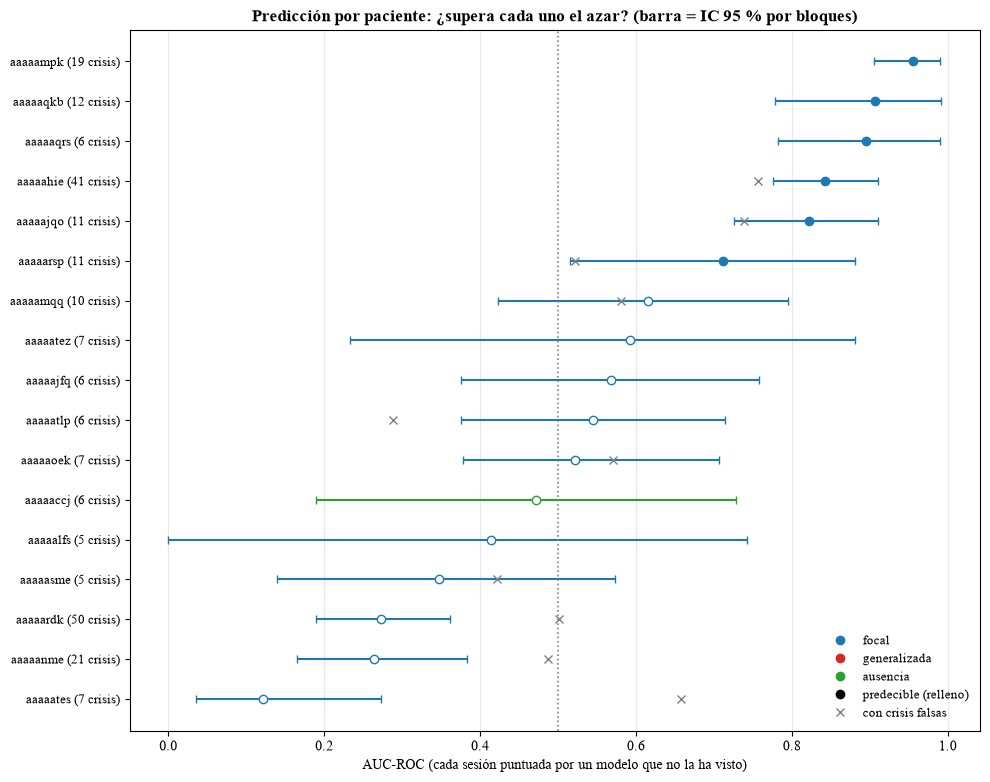

In [12]:
# 1) La combinación principal
principal = resultados.loc[PRINCIPAL].sort_values('AUC')
falsas_principal = resultados.loc[(PRINCIPAL[0], PRINCIPAL[1], 'falsas')]
fila_principal = resumen.loc[clave_principal]
k_pred, n_pac, p_valor = int(fila_principal['predecibles']), int(fila_principal['pacientes']), float(fila_principal['p (más que el azar)'])
tasa_azar = max(fila_principal['% con crisis falsas'] / 100, 0.025)
esperados = tasa_azar * n_pac
lideres_fila = resumen.loc[(clave_principal[0], clave_principal[1], 'líderes')] if (clave_principal[0], clave_principal[1], 'líderes') in resumen.index else None
pred_lideres = (resultados.loc[(PRINCIPAL[0], PRINCIPAL[1], 'líderes')].query('predecible').index.tolist()
                if lideres_fila is not None else [])
predecibles = principal.index[principal.predecible].tolist()

# 2) Veredicto con las reglas de §7
texto_pacientes = ', '.join(f'{p} ({decimal(principal.loc[p, "AUC"])})' for p in predecibles) or 'ninguno'
if k_pred and p_valor < 0.05:
    veredicto = ('✅ Hay predicción por paciente',
                 f'<b>{k_pred} de {n_pac} pacientes</b> son predecibles (por azar se esperarían {decimal(esperados, 1)}; p = {decimal(p_valor, 3)}): '
                 f'{texto_pacientes}. Con solo crisis líderes, {len(pred_lideres)} de {int(lideres_fila["pacientes"]) if lideres_fila is not None else 0}. '
                 'En esos pacientes el EEG cambia antes de la crisis de una forma que se repite de un día a otro.')
elif k_pred:
    veredicto = ('🟡 Algunos pacientes salen predecibles, pero no más de los que da el azar',
                 f'{k_pred} de {n_pac} ({texto_pacientes}), y con crisis falsas sale un {decimal(100 * tasa_azar, 1)} % '
                 f'(se esperarían {decimal(esperados, 1)}; p = {decimal(p_valor, 3)}). No se puede decir que sean predecibles de verdad: '
                 'hacen falta más crisis por paciente (CHB-MIT) para confirmarlo.')
else:
    veredicto = ('🔴 Ningún paciente es predecible',
                 f'Ningún intervalo queda entero por encima de 0,5 (AUC mediana {decimal(fila_principal["AUC mediana"])}). '
                 'Con 2 min de preictal y las crisis de TUSZ, tampoco por paciente hay un aviso que se repita entre sesiones.')
mostrar_destacado(f'Predicción por paciente · {veredicto[0]}', veredicto[1],
                  resumen.loc[[clave_principal]].T.rename(columns=lambda c: ' · '.join(c)),
                  f'Combinación principal fijada antes de mirar: {" · ".join(clave_principal)}. Detección (⚡ frente a 💤) por paciente: '
                  f'mediana {decimal(deteccion.median())}.')

# 3) Figura: la AUC de cada paciente con su intervalo, y la de sus crisis falsas
grupo_de = tabla_pacientes.grupo.astype(str)
colores_grupo = {'focal': '#1f77b4', 'generalizada': '#d62728', 'ausencia': '#2ca02c'}
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(principal) + 1.8))
    pos_y = np.arange(len(principal))
    for i, (p, r) in enumerate(principal.iterrows()):
        color = colores_grupo.get(grupo_de.get(p, '').split('/')[0], COLORES_ESQUEMA['negro'])
        ax.errorbar(r.AUC, i, xerr=[[r.AUC - r['IC inferior']], [r['IC superior'] - r.AUC]], fmt='o', color=color, ecolor=color,
                    capsize=3, mfc=color if r.predecible else 'white')
        if p in falsas_principal.index:
            ax.plot(falsas_principal.loc[p, 'AUC'], i, 'x', color='gray')
    ax.axvline(0.5, color='gray', ls=':', lw=1.2)
    ax.set_yticks(pos_y, [f'{p} ({int(r["crisis puntuadas"])} crisis)' for p, r in principal.iterrows()], fontsize=9)
    ax.set_xlabel('AUC-ROC (cada sesión puntuada por un modelo que no la ha visto)')
    ax.set_title('Predicción por paciente: ¿supera cada uno el azar? (barra = IC 95 % por bloques)', fontsize=12, fontweight='bold')
    leyenda = [Line2D([], [], marker='o', ls='', color=c, label=g) for g, c in colores_grupo.items()]
    leyenda += [Line2D([], [], marker='o', ls='', color='black', label='predecible (relleno)'),
                Line2D([], [], marker='x', ls='', color='gray', label='con crisis falsas')]
    ax.legend(handles=leyenda, frameon=False, loc='lower right', fontsize=9)
    ax.grid(alpha=0.3, axis='x')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'auc_por_paciente.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Una fila por paciente (entre paréntesis, sus crisis puntuadas), ordenados por AUC. El punto es su AUC y la barra su intervalo del 95 %; relleno = predecible (la barra entera a la derecha de 0,5). El color es el grupo de inicio. La cruz gris es el mismo paciente con **crisis falsas**: debería quedar cerca de 0,5.

✅ **Qué deberías ver:** si hay aviso por paciente, varios puntos rellenos y sus cruces grises lejos de ellos. Si los puntos rellenos aparecen igual de a menudo que cruces grises lejos de 0,5, es suerte.

## 9. Por grupo de inicio (focal, generalizada, ausencia)

> 🎯 **Qué hacemos:** la combinación principal, separada por el grupo de inicio de las crisis de cada paciente.
>
> 🤔 **Por qué:** cada tipo de crisis puede avisar de forma distinta. Ojo: con 2-3 pacientes por grupo, esto orienta, no demuestra.

In [13]:
por_grupo = principal.join(tabla_pacientes[['grupo', 'tipos']]).groupby('grupo').agg(
    pacientes=('AUC', 'size'), AUC_mediana=('AUC', 'median'), predecibles=('predecible', 'sum'),
    crisis_avisadas=('crisis avisadas', 'sum'), crisis_puntuadas=('crisis puntuadas', 'sum'))
por_grupo = por_grupo.rename(columns={'AUC_mediana': 'AUC mediana', 'crisis_avisadas': 'crisis avisadas', 'crisis_puntuadas': 'crisis puntuadas'})
display(con_separadores(por_grupo.rename(index=con_icono), decimales=2))

,pacientes,AUC mediana,predecibles,crisis avisadas,crisis puntuadas
grupo,,,,,
🔹 ausencia,1,"0,47",0,0,6
♦️ focal,8,"0,57",3,34,94
focal/generalizada,8,"0,59",3,34,130


## 10. El resultado → tablas, puntuaciones y `configuracion.json`

In [14]:
# 1) Tablas
tabla_pacientes.to_csv(RUTA_RESULTADOS / 'pacientes.csv')
mostrar_fichero(RUTA_RESULTADOS / 'pacientes.csv', 'los pacientes que entran: partición, grupo, tipos, crisis, sesiones, ventanas de cada clase y crisis líderes')
resultados.reset_index().to_csv(RUTA_RESULTADOS / 'resultados_por_paciente.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'resultados_por_paciente.csv', 'una fila por combinación y paciente: AUC con su intervalo, AUC en la misma sesión, crisis avisadas y si es predecible')
resumen.reset_index().to_csv(RUTA_RESULTADOS / 'resumen_combinaciones.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'resumen_combinaciones.csv', 'una fila por combinación: AUC mediana, predecibles, tasa con crisis falsas y test frente al azar')
deteccion.rename_axis('paciente').reset_index().to_csv(RUTA_RESULTADOS / 'deteccion_por_paciente.csv', index=False)

# 2) Puntuaciones de la combinación principal (cada ventana, puntuada sin haber visto su sesión)
puntos = filas[['id_ventana', 'split', 'patient', 'sesion', 'file', 'clase', 'etiqueta', 'grupo', 'crisis_id', 'lider', 'minutos_desde_crisis_anterior']].copy()
puntos['puntuacion_principal'] = np.round(puntuaciones[PRINCIPAL], 5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_principal.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_principal.csv', 'una fila por ventana: su puntuación con la combinación principal (sin haber visto su sesión)')

# 3) configuracion.json
config = {
    'conjunto': CONJUNTO, 'splits_pacientes': SPLITS_PACIENTES, 'eval_usado': bool(INCLUIR_EVAL),
    'minimo_crisis': MINIMO_CRISIS, 'minimo_sesiones': MINIMO_SESIONES, 'minimo_crisis_lideres': MINIMO_CRISIS_LIDERES,
    'max_interictal_paciente': MAX_INTERICTAL_PACIENTE, 'contextos_s': CONTEXTOS, 'modelos': MODELOS_PROBAR, 'lider_min': LIDER_MIN,
    'principal': {'contexto_s': PRINCIPAL[0], 'modelo': PRINCIPAL[1], 'crisis': PRINCIPAL[2]},
    'pacientes': PACIENTES, 'pacientes_con_lideres': CON_LIDERES,
    'veredicto': veredicto[0], 'predecibles': predecibles, 'predecibles_lideres': pred_lideres,
    'predecibles_n': k_pred, 'pacientes_n': n_pac, 'tasa_azar': float(tasa_azar), 'p_valor': p_valor,
    'deteccion_mediana': float(deteccion.median()) if len(deteccion) else None,
    'especificidad': ESPECIFICIDAD, 'n_bootstrap': N_BOOTSTRAP, 'semilla': SEMILLA, 'versiones': versiones_usadas,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, ensure_ascii=False, indent=4), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'los botones, los pacientes y el veredicto')

💾 **Guardado `pacientes.csv`** · 1,4 KB · 21 filas × 12 columnas  
*Qué guarda:* los pacientes que entran: partición, grupo, tipos, crisis, sesiones, ventanas de cada clase y crisis líderes. *Abajo:* las 5 primeras filas.

,paciente,split,grupo,tipos,crisis con ⏳,sesiones,sesiones con ⏳,⏳ ventanas,💤 ventanas,⚡ ventanas,crisis líderes,sesiones con líderes
0,aaaaaccj,🔵 train,🔹 ausencia,absz,6,3,3,337,319,24,3,3
1,aaaaahie,🟡 dev,♦️ focal,fnsz,41,32,9,2289,3510,1557,15,8
2,aaaaajfq,🔵 train,focal/generalizada,cpsz/fnsz/gnsz,6,12,3,338,2799,218,1,1
3,aaaaajqo,🔵 train,♦️ focal,cpsz,11,17,3,575,3705,1586,5,3
4,aaaaalfs,🔵 train,♦️ focal,fnsz,5,3,3,268,105,373,2,2


💾 **Guardado `resultados_por_paciente.csv`** · 18,8 KB · 148 filas × 14 columnas  
*Qué guarda:* una fila por combinación y paciente: AUC con su intervalo, AUC en la misma sesión, crisis avisadas y si es predecible. *Abajo:* las 5 primeras filas.

,contexto,modelo,crisis,paciente,rondas (sesiones con ⏳),AUC,IC inferior,IC superior,AUC misma sesión,crisis avisadas,crisis puntuadas,⏳ puntuadas,💤 puntuadas,predecible
0,4,logistica,todas,aaaaaccj,3,0.392203,0.167946,0.610975,0.523760,0,6,337,319,False
1,4,logistica,todas,aaaaahie,9,0.847283,0.789158,0.904046,0.606998,24,41,2289,3510,True
2,4,logistica,todas,aaaaajfq,3,0.669706,0.572101,0.757761,0.786353,0,6,338,2799,True
3,4,logistica,todas,aaaaajqo,3,0.826266,0.753039,0.897295,0.474811,3,11,575,3705,True
4,4,logistica,todas,aaaaalfs,3,0.276013,0.062805,0.593696,0.280740,0,5,268,105,False


💾 **Guardado `resumen_combinaciones.csv`** · 1,1 KB · 8 filas × 11 columnas  
*Qué guarda:* una fila por combinación: AUC mediana, predecibles, tasa con crisis falsas y test frente al azar. *Abajo:* las 5 primeras filas.

,contexto,modelo,crisis,pacientes,AUC mediana,AUC misma sesión (mediana),predecibles,% predecibles,% con crisis falsas,p (más que el azar),crisis avisadas
0,4 s,regresión logística,todas,17,0.573682,0.531789,6,35.294118,20.0,0.105701,71 de 230
1,4 s,regresión logística,líderes,10,0.562905,0.525342,4,40.000000,20.0,0.120874,14 de 50
2,4 s,XGBoost,todas,17,0.468790,0.571993,6,35.294118,20.0,0.105701,67 de 230
3,4 s,XGBoost,líderes,10,0.555248,0.528333,3,30.000000,20.0,0.322200,12 de 50
4,60 s,regresión logística,todas,17,0.568376,0.485975,6,35.294118,20.0,0.105701,68 de 230


💾 **Guardado `puntuaciones_principal.csv`** · 8,4 MB · 61.670 filas × 12 columnas  
*Qué guarda:* una fila por ventana: su puntuación con la combinación principal (sin haber visto su sesión). *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,sesion,file,clase,etiqueta,grupo,crisis_id,lider,minutos_desde_crisis_anterior,puntuacion_principal
0,aaaaaccj_s001_t000_preictal_000000000_000034647,🔵 train,aaaaaccj,aaaaaccj_s001,aaaaaccj_s001_t000,⏳ preictal,1,🔹 ausencia,aaaaaccj_s001_t000_c00,True,NaN,0.39248
1,aaaaaccj_s001_t000_preictal_000000000_000035159,🔵 train,aaaaaccj,aaaaaccj_s001,aaaaaccj_s001_t000,⏳ preictal,1,🔹 ausencia,aaaaaccj_s001_t000_c00,True,NaN,0.36878
2,aaaaaccj_s001_t000_preictal_000000000_000035671,🔵 train,aaaaaccj,aaaaaccj_s001,aaaaaccj_s001_t000,⏳ preictal,1,🔹 ausencia,aaaaaccj_s001_t000_c00,True,NaN,0.54885
3,aaaaaccj_s001_t000_preictal_000000000_000036183,🔵 train,aaaaaccj,aaaaaccj_s001,aaaaaccj_s001_t000,⏳ preictal,1,🔹 ausencia,aaaaaccj_s001_t000_c00,True,NaN,0.53381
4,aaaaaccj_s001_t000_preictal_000000000_000036695,🔵 train,aaaaaccj,aaaaaccj_s001,aaaaaccj_s001_t000,⏳ preictal,1,🔹 ausencia,aaaaaccj_s001_t000_c00,True,NaN,0.43968


💾 **Guardado `configuracion.json`** · 2,3 KB · 26 claves  
*Qué guarda:* los botones, los pacientes y el veredicto. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
splits_pacientes,"[""train"", ""dev""]"
eval_usado,false
minimo_crisis,5
minimo_sesiones,2
minimo_crisis_lideres,3
max_interictal_paciente,4000
contextos_s,"[4, 60]"
modelos,"{""logistica"": {""C"": 0.01}, ""xgboost"": {""max_depth"": 3, ""n_estimators"": 200, ""learning_rate…"


## 11. Resumen → `summary.txt` y conclusiones

In [15]:
lineas = [
    f'F03.03c · Predicción por paciente: {config["fecha"]} · conjunto {CONJUNTO} · semilla {SEMILLA} · '
    + ('🟢 eval incluido' if INCLUIR_EVAL else '🟢 eval no usado'),
    f'{len(PACIENTES)} pacientes ({", ".join(f"{con_icono(s)} {n}" for s, n in tabla_pacientes.split.value_counts().items())}) · '
    f'{numero_legible(int((filas.etiqueta == 1).sum()))} ⏳ · {numero_legible(int((filas.etiqueta == 0).sum()))} 💤',
    f'Detección por paciente (⚡ frente a 💤): mediana {decimal(deteccion.median())}',
    f'Principal ({" · ".join(clave_principal)}): {k_pred} de {n_pac} predecibles · AUC mediana {decimal(fila_principal["AUC mediana"])} · '
    f'azar (crisis falsas) {decimal(100 * tasa_azar, 1)} % · p = {decimal(p_valor, 3)}',
    f'Veredicto: {veredicto[0]}',
]
texto = ('=== F03.03c · Predicción por paciente ===\n' + '\n'.join(lineas) + '\n\n--- Resumen por combinación ---\n' + resumen.to_string()
         + '\n\n--- Combinación principal, por paciente ---\n' + principal.round(3).to_string()
         + '\n\n--- Por grupo de inicio ---\n' + por_grupo.round(3).to_string() + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen en texto')

# Conclusiones, escritas solas
mediana_misma = fila_principal['AUC misma sesión (mediana)']
conclusiones = [
    (f'**1. La cadena.** Detecta las crisis dentro de cada paciente (⚡ frente a 💤: mediana {decimal(deteccion.median())}), '
     'así que la medición de la predicción es fiable.') if cadena_ok else
    f'**1. La cadena.** La detección por paciente sale baja (mediana {decimal(deteccion.median())}): revisar antes de sacar conclusiones.',
    f'**2. El veredicto: {veredicto[0]}.** ' + re.sub('<[^>]+>', '', veredicto[1]),
    f'**3. Sin la pista de la sesión.** Comparando solo ⏳ y 💤 de la misma sesión, la AUC mediana es {decimal(mediana_misma)}: '
    + ('se mantiene, así que no depende de reconocer la grabación.' if mediana_misma > 0.55 else 'se queda cerca del azar.'),
    f'**4. Crisis líderes.** ' + (f'Con solo crisis líderes ({len(CON_LIDERES)} pacientes) hay {len(pred_lideres)} predecibles.'
                                  if lideres_fila is not None else 'No hay pacientes con suficientes crisis líderes para medirlo.'),
    '**5. Para la memoria:** la predicción por paciente es el planteamiento que respalda la literatura. En TUSZ está limitada por las pocas '
    'crisis por paciente y por los racimos; CHB-MIT (registros continuos largos, más crisis por paciente) es el siguiente paso natural.',
]
display(Markdown('\n\n'.join(conclusiones)))

💾 **Guardado `summary.txt`** · 5,8 KB · 46 líneas  
*Qué guarda:* el resumen en texto. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== F03.03c · Predicción por paciente ===
2,F03.03c · Predicción por paciente: 2026-11-19 16:56 · conjunto general · semilla 42 · 🟢 eval no usado
3,"21 pacientes (🔵 train 13, 🟡 dev 8) · 13.568 ⏳ · 48.102 💤"
4,"Detección por paciente (⚡ frente a 💤): mediana 0,92"
5,"Principal (60 s · regresión logística · todas): 6 de 17 predecibles · AUC mediana 0,57 · azar (crisis falsas) 20,0 % · p = 0,106"


**1. La cadena.** Detecta las crisis dentro de cada paciente (⚡ frente a 💤: mediana 0,92), así que la medición de la predicción es fiable.

**2. El veredicto: 🟡 Algunos pacientes salen predecibles, pero no más de los que da el azar.** 6 de 17 (aaaaarsp (0,71), aaaaajqo (0,82), aaaaahie (0,84), aaaaaqrs (0,90), aaaaaqkb (0,91), aaaaampk (0,96)), y con crisis falsas sale un 20,0 % (se esperarían 3,4; p = 0,106). No se puede decir que sean predecibles de verdad: hacen falta más crisis por paciente (CHB-MIT) para confirmarlo.

**3. Sin la pista de la sesión.** Comparando solo ⏳ y 💤 de la misma sesión, la AUC mediana es 0,49: se queda cerca del azar.

**4. Crisis líderes.** Con solo crisis líderes (12 pacientes) hay 4 predecibles.

**5. Para la memoria:** la predicción por paciente es el planteamiento que respalda la literatura. En TUSZ está limitada por las pocas crisis por paciente y por los racimos; CHB-MIT (registros continuos largos, más crisis por paciente) es el siguiente paso natural.

## 12. Cómo sigue

- **Si sale ✅:** confirmar con `INCLUIR_EVAL = True` (más pacientes, sin tocar nada más) y llevar la combinación principal a **CHB-MIT**, que tiene más crisis por paciente y registros continuos. Mirar en F05 (XAI) qué canales y bandas usa el modelo en los pacientes predecibles.
- **Si sale 🟡:** la señal existe en algún paciente, pero hacen falta más crisis por paciente para separarla de la suerte: **CHB-MIT**.
- **Si sale 🔴:** con 2 min de preictal y las crisis de TUSZ no hay aviso que se repita. Es un resultado defendible (con todos los controles de F03.03b y este) y deja **CHB-MIT** como el sitio donde probar la predicción con preictales largos (30-60 min).

> 📝 **Para la memoria.** Este notebook responde a la pregunta que haría cualquier revisor después de F03.03b: "¿y por paciente?". La respuesta está medida contra el azar real (crisis falsas), sin la pista de la grabación (sesión fuera) y sin el después de la crisis anterior (crisis líderes).

## 13. Archivos generados

En `outputs/fase_03/<conjunto>/03c_por_paciente/`:

- `pacientes.csv`: los pacientes que entran y sus datos.
- `resultados_por_paciente.csv`: cada combinación y paciente, con su AUC, intervalo, AUC en la misma sesión y crisis avisadas.
- `resumen_combinaciones.csv`: el resumen por combinación, con la tasa de azar (crisis falsas) y el test.
- `deteccion_por_paciente.csv`: la comprobación de la cadena (⚡ frente a 💤).
- `puntuaciones_principal.csv`: la puntuación de cada ventana con la combinación principal.
- `configuracion.json` y `summary.txt`.
- `figuras/auc_por_paciente.png`.
- Almacén de características: `outputs/fase_03/02_linea_base/caracteristicas/por_paciente_<conjunto>/`.